In [77]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re
import nltk
import spacy
import string
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Bidirectional, LSTM, GRU, Dense
from keras.callbacks import EarlyStopping

In [78]:
!pip -q install accelerate -U
!pip -q install transformers[torch]
from transformers import pipeline

In [79]:
df = pd.read_json("/content/Sarcasm_Headlines_Dataset_v2.json",lines=True)

In [80]:
df.head()

,is_sarcastic,headline,article_link
0,1,thirtysomething scientists unveil doomsday clo...,https://www.theonion.com/thirtysomething-scien...
1,0,dem rep. totally nails why congress is falling...,https://www.huffingtonpost.com/entry/donna-edw...
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-...
3,1,inclement weather prevents liar from getting t...,https://local.theonion.com/inclement-weather-p...
4,1,mother comes pretty close to using word 'strea...,https://www.theonion.com/mother-comes-pretty-c...


In [81]:
#drop 'article_link' column as not required for the analysis
df = df.drop('article_link', axis=1)

In [82]:
df.isnull().sum()

,0
is_sarcastic,0
headline,0


In [83]:
df.duplicated().sum()

np.int64(116)

In [84]:
df.drop_duplicates(inplace=True)

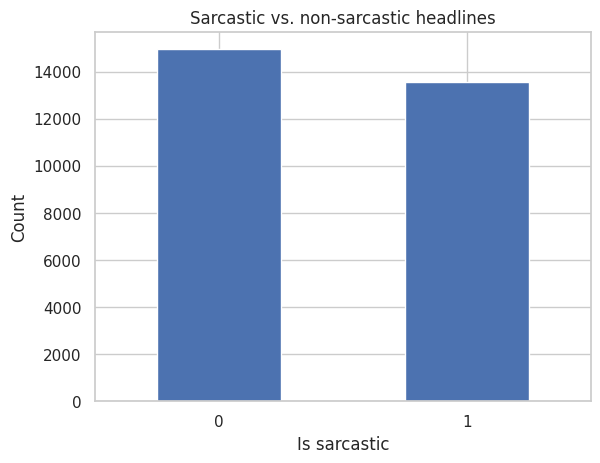

In [85]:
# Bar chart to visualize the distribution of sarcastic and non-sarcastic headlines
df["is_sarcastic"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Is sarcastic")
plt.ylabel("Count")
plt.title("Sarcastic vs. non-sarcastic headlines")
plt.xticks(rotation=0)
plt.show()


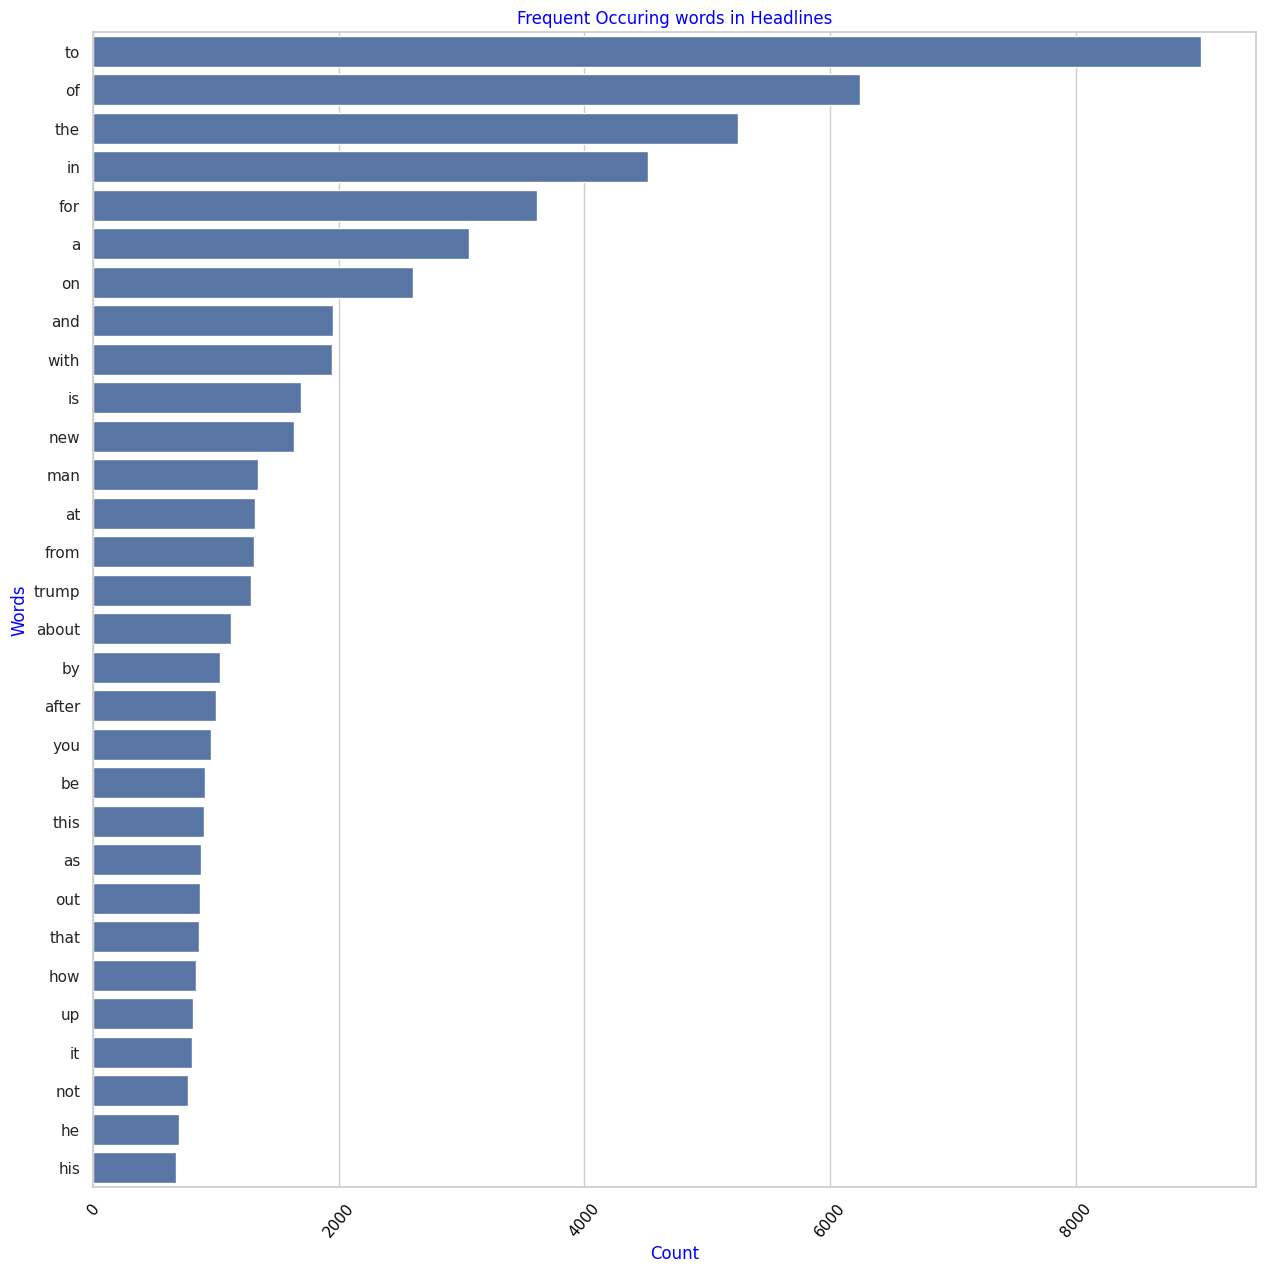

In [86]:
# Most common words in the headlines
from collections import Counter #import Counter for finding most common words

text = df['headline']
words = text.str.split(expand=True).unstack()
result_count = Counter(words).most_common()
result_df = pd.DataFrame(result_count).reset_index().drop(0) #converting to Dataframe and drop the Nones values
#result_df
#vizualize result
sns.set_theme(style="whitegrid")
f, ax = plt.subplots(figsize=(15, 15))
sns.barplot(y=result_df[0][0:30], x=result_df[1][0:30], data=result_df, palette=None)
plt.ylabel('Words', color="blue")  # Add an x-label to the axes.
plt.xlabel('Count', color="blue")  # Add a y-label to the axes.
plt.title("Frequent Occuring words in Headlines", color="blue")
plt.xticks(rotation=50);
ax.tick_params(axis='x', colors='black')
plt.show()

In [87]:
# stopwords removal
from nltk.corpus import stopwords
nltk.download('stopwords')

STOPWORDS = set(stopwords.words('english'))
def Remove_Stopwords(p_text):
    return " ".join([word for word in str(p_text).split() if word not in STOPWORDS])

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [88]:
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

lemmatizer = WordNetLemmatizer()
wordnet_map = {"N":wordnet.NOUN, "V":wordnet.VERB, "J":wordnet.ADJ, "R":wordnet.ADV}

def Lemmatize_Words(p_text):
    pos_tagged_text = nltk.pos_tag(p_text.split())
    return " ".join([lemmatizer.lemmatize(word, wordnet_map.get(pos[0], wordnet.NOUN)) for word, pos in pos_tagged_text])

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


In [89]:
# Chat word conversion
chat_words_str = """
AFAIK=As Far As I Know
AFK=Away From Keyboard
ASAP=As Soon As Possible
ATK=At The Keyboard
ATM=At The Moment
A3=Anytime, Anywhere, Anyplace
BAK=Back At Keyboard
BBL=Be Back Later
BBS=Be Back Soon
BFN=Bye For Now
B4N=Bye For Now
BRB=Be Right Back
BRT=Be Right There
BTW=By The Way
B4=Before
B4N=Bye For Now
CU=See You
CUL8R=See You Later
CYA=See You
FAQ=Frequently Asked Questions
FC=Fingers Crossed
FWIW=For What It's Worth
FYI=For Your Information
GAL=Get A Life
GG=Good Game
GN=Good Night
GMTA=Great Minds Think Alike
GR8=Great!
G9=Genius
IC=I See
ICQ=I Seek you (also a chat program)
ILU=ILU: I Love You
IMHO=In My Honest/Humble Opinion
IMO=In My Opinion
IOW=In Other Words
IRL=In Real Life
KISS=Keep It Simple, Stupid
LDR=Long Distance Relationship
LMAO=Laugh My A.. Off
LOL=Laughing Out Loud
LTNS=Long Time No See
L8R=Later
MTE=My Thoughts Exactly
M8=Mate
NRN=No Reply Necessary
OIC=Oh I See
PITA=Pain In The A..
PRT=Party
PRW=Parents Are Watching
ROFL=Rolling On The Floor Laughing
ROFLOL=Rolling On The Floor Laughing Out Loud
ROTFLMAO=Rolling On The Floor Laughing My A.. Off
SK8=Skate
STATS=Your sex and age
ASL=Age, Sex, Location
THX=Thank You
TTFN=Ta-Ta For Now!
TTYL=Talk To You Later
U=You
U2=You Too
U4E=Yours For Ever
WB=Welcome Back
WTF=What The F...
WTG=Way To Go!
WUF=Where Are You From?
W8=Wait...
7K=Sick:-D Laugher
"""

chat_words_map_dict = {}
chat_words_list = []
for line in chat_words_str.split("\n"):
    if line != "":
        cw = line.split("=")[0]
        cw_expanded = line.split("=")[1]
        chat_words_list.append(cw)
        chat_words_map_dict[cw] = cw_expanded
chat_words_list = set(chat_words_list)

def Chat_Words_Conversion(p_text):
    new_text = []
    for word in p_text.split():
        if word.upper() in chat_words_list:
            new_text.append(chat_words_map_dict[word.upper()])
        else:
            new_text.append(word)
    return " ".join(new_text)

In [90]:
# Spelling Correction
!pip install pyspellchecker
from spellchecker import SpellChecker

spell = SpellChecker()
def Correct_Spellings(p_text):
    corrected_text = []
    misspelled_words = spell.unknown(p_text.split())
    for word in p_text.split():
        if word in misspelled_words:
            corrected = spell.correction(word)
            corrected_text.append(corrected if corrected is not None else word)
        else:
            corrected_text.append(word)
    return " ".join(corrected_text)

In [91]:
# Punctuation removal
PUNCT_TO_REMOVE = string.punctuation
PUNCT_TO_REMOVE = PUNCT_TO_REMOVE.replace("'", "")

def Remove_Punctuation(p_text):
    return p_text.translate(str.maketrans('', '', PUNCT_TO_REMOVE))

In [92]:
def process_single_text(p_text):
    p_text = p_text.strip().lower()
    p_text = re.sub(r'http\S+', '', p_text)
    p_text = Remove_Punctuation(p_text)
    p_text = Chat_Words_Conversion(p_text)
    # Commented Correct_Spellings as taking too much time
    #p_text = Correct_Spellings(p_text)
    p_text = Remove_Stopwords(p_text)
    p_text = Lemmatize_Words(p_text)
    return p_text

In [93]:
!pip install pandarallel
from pandarallel import pandarallel
pandarallel.initialize(progress_bar = True)

INFO: Pandarallel will run on 1 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.


In [94]:
# Text Preprocessing
def Clean_Data(p_df):
  p_df['headline'] = p_df['headline'].astype(str).parallel_apply(process_single_text) #parallel processing
  return p_df

In [95]:
df_bck = df.copy()

In [96]:
# Preprocess Data
df_clean = Clean_Data(df)

In [97]:
df_clean.head()

,is_sarcastic,headline
0,1,thirtysomething scientist unveil doomsday cloc...
1,0,dem rep totally nails congress fall short gend...
2,0,eat veggie 9 deliciously different recipe
3,1,inclement weather prevents liar get work
4,1,mother come pretty close use word 'streaming' ...


In [98]:
x_train,x_test,y_train,y_test = train_test_split(df_clean["headline"], df_clean["is_sarcastic"], test_size = 0.2 , random_state = 42)

In [99]:
x_train.head()

,headline
2827,new law require welfare recipient submit sweat...
24271,jake tapper's grim reminder steve bannon probl...
20969,journalist refuse take nonanswer answer
5678,report shit last night trash night
5267,importance first responder


In [100]:
y_train.head()

,is_sarcastic
2827,1
24271,0
20969,0
5678,1
5267,0


In [101]:
from tensorflow.keras.preprocessing.text import Tokenizer

VOCAB_SIZE = 10000

# Initialize Tokenizer
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<unk>")

# Fit tokenizer on training texts
tokenizer.fit_on_texts(x_train)

# Convert texts to sequences of integers
x_train = tokenizer.texts_to_sequences(x_train)
x_test = tokenizer.texts_to_sequences(x_test)

In [102]:
# Pad sequences to a fixed length (in this case, 75)
max_length = 75
x_train = pad_sequences(x_train, maxlen=max_length)
x_test = pad_sequences(x_test, maxlen=max_length)

In [104]:
x_train

array([[   0,    0,    0, ...,  400,   38,  113],
       [   0,    0,    0, ..., 1712,  291,    4],
       [   0,    0,    0, ...,   15,    1,  942],
       ...,
       [   0,    0,    0, ...,  735,  414,  103],
       [   0,    0,    0, ..., 1158, 4857,  597],
       [   0,    0,    0, ..., 5432,  202, 3887]], dtype=int32)

In [105]:
model_names = []
training_accuracy_scores = []
testing_accuracy_scores = []
overfitting_status = []
overfitting_threshold = 0.05

In [106]:
def Prepare_Evalution_Report():
    results_df = pd.DataFrame({
        'Model': model_names,
        'Train Accuracy': training_accuracy_scores,
        'Test Accuracy': testing_accuracy_scores,
        'Overfitting (Y/N)': overfitting_status
    })

    results_df = results_df.sort_values(by='Test Accuracy', ascending=False).reset_index(drop=True)
    return results_df

In [108]:
# RNN Model

model1 = Sequential()
model1.add(Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=max_length))
model1.add(SimpleRNN(units=64))
model1.add(Dense(units=1, activation='sigmoid'))
model1.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model1.fit(x_train, y_train, epochs=10, verbose=1)
model_names.append("SimpleRNN")
train_accuracy = model1.evaluate(x_train, y_train)[1]
test_accuracy = model1.evaluate(x_test, y_test)[1]
training_accuracy_scores.append(np.round(train_accuracy, 4))
testing_accuracy_scores.append(np.round(test_accuracy, 4))
overfitting_status.append("Y" if abs(train_accuracy - test_accuracy) > overfitting_threshold else "N")

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


713/713 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.7372 - loss: 0.5143
Epoch 2/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8838 - loss: 0.2841
Epoch 3/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9554 - loss: 0.1199
Epoch 4/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9729 - loss: 0.0774
Epoch 5/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9897 - loss: 0.0297
Epoch 6/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9954 - loss: 0.0144
Epoch 7/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9969 - loss: 0.0100
Epoch 8/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9969 - loss: 0.0099
Epoch 9/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9964 - loss: 0.0105
Epoch 10/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9944 - loss: 0.0155
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9914 - loss: 0.0231
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7320 - loss: 1.508

In [109]:
train_accuracy

0.9913604259490967

In [110]:
test_accuracy

0.7319768667221069

In [111]:
# LSTM Model

model2 = Sequential()
model2.add(Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=max_length))
model2.add(LSTM(units=64))
model2.add(Dense(units=1, activation='sigmoid'))
model2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model2.fit(x_train, y_train, epochs=10, verbose=1)
model_names.append("LSTM")
train_accuracy = model2.evaluate(x_train, y_train)[1]
test_accuracy = model2.evaluate(x_test, y_test)[1]
training_accuracy_scores.append(np.round(train_accuracy, 4))
testing_accuracy_scores.append(np.round(test_accuracy, 4))
overfitting_status.append("Y" if abs(train_accuracy - test_accuracy) > overfitting_threshold else "N")

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


713/713 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.7549 - loss: 0.4872
Epoch 2/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.8751 - loss: 0.2948
Epoch 3/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.9229 - loss: 0.1942
Epoch 4/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9468 - loss: 0.1314
Epoch 5/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9631 - loss: 0.0943
Epoch 6/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9724 - loss: 0.0684
Epoch 7/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9799 - loss: 0.0530
Epoch 8/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9850 - loss: 0.0381
Epoch 9/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9902 - loss: 0.0263
Epoch 10/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9925 - loss: 0.0207
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9945 - loss: 0.0170
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7760 - loss: 1.3785

In [112]:
train_accuracy, test_accuracy

(0.9945180416107178, 0.7760041952133179)

In [113]:
# GRU Model

model3 = Sequential()
model3.add(Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=max_length))
model3.add(GRU(units=64))
model3.add(Dense(units=1, activation='sigmoid'))
model3.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model3.fit(x_train, y_train, epochs=10, verbose=1)
model_names.append("GRU")
train_accuracy = model3.evaluate(x_train, y_train)[1]
test_accuracy = model3.evaluate(x_test, y_test)[1]
training_accuracy_scores.append(np.round(train_accuracy, 4))
testing_accuracy_scores.append(np.round(test_accuracy, 4))
overfitting_status.append("Y" if abs(train_accuracy - test_accuracy) > overfitting_threshold else "N")

Epoch 1/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.7478 - loss: 0.4965
Epoch 2/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8735 - loss: 0.2908
Epoch 3/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9257 - loss: 0.1865
Epoch 4/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9550 - loss: 0.1205
Epoch 5/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9720 - loss: 0.0763
Epoch 6/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9822 - loss: 0.0495
Epoch 7/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9886 - loss: 0.0337
Epoch 8/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9922 - loss: 0.0233
Epoch 9/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9943 - loss: 0.0174
Epoch 10/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9963 - loss: 0.0116
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9968 - loss: 0.0097
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7786 - l

In [114]:
train_accuracy, test_accuracy

(0.9968423843383789, 0.7786353230476379)

In [115]:
# Bidirectional RNN Model

model4 = Sequential()
model4.add(Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=max_length))
model4.add(Bidirectional(SimpleRNN(units=64)))
model4.add(Dense(units=1, activation='sigmoid'))
model4.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model4.fit(x_train, y_train, epochs=10, verbose=1)
model_names.append("Bidirectional SimpleRNN")
train_accuracy = model4.evaluate(x_train, y_train)[1]
test_accuracy = model4.evaluate(x_test, y_test)[1]
training_accuracy_scores.append(np.round(train_accuracy, 4))
testing_accuracy_scores.append(np.round(test_accuracy, 4))
overfitting_status.append("Y" if abs(train_accuracy - test_accuracy) > overfitting_threshold else "N")

Epoch 1/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.7363 - loss: 0.5120
Epoch 2/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.8731 - loss: 0.3000
Epoch 3/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9543 - loss: 0.1244
Epoch 4/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9782 - loss: 0.0640
Epoch 5/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9753 - loss: 0.0645
Epoch 6/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9911 - loss: 0.0258
Epoch 7/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9961 - loss: 0.0119
Epoch 8/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9972 - loss: 0.0084
Epoch 9/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9966 - loss: 0.0098
Epoch 10/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9932 - loss: 0.0177
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9977 - loss: 0.0070
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accu

In [116]:
train_accuracy, test_accuracy

(0.9976756572723389, 0.755832314491272)

In [117]:
# Bidirectional LSTM Model

model5 = Sequential()
model5.add(Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=max_length))
model5.add(Bidirectional(LSTM(units=64)))
model5.add(Dense(units=1, activation='sigmoid'))
model5.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model5.fit(x_train, y_train, epochs=10, verbose=1)
model_names.append("Bidirectional LSTM")
train_accuracy = model5.evaluate(x_train, y_train)[1]
test_accuracy = model5.evaluate(x_test, y_test)[1]
training_accuracy_scores.append(np.round(train_accuracy, 4))
testing_accuracy_scores.append(np.round(test_accuracy, 4))
overfitting_status.append("Y" if abs(train_accuracy - test_accuracy) > overfitting_threshold else "N")

Epoch 1/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.7527 - loss: 0.4902
Epoch 2/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8723 - loss: 0.2964
Epoch 3/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9219 - loss: 0.1964
Epoch 4/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9475 - loss: 0.1358
Epoch 5/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9632 - loss: 0.0955
Epoch 6/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9730 - loss: 0.0688
Epoch 7/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9807 - loss: 0.0511
Epoch 8/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9863 - loss: 0.0370
Epoch 9/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9890 - loss: 0.0282
Epoch 10/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9926 - loss: 0.0215
713/713 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9959 - loss: 0.0131
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 

In [118]:
train_accuracy, test_accuracy

(0.9958775639533997, 0.7779337167739868)

In [119]:
# Bidirectional GRU Model

model6 = Sequential()
model6.add(Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=max_length))
model6.add(Bidirectional(GRU(units=64)))
model6.add(Dense(units=1, activation='sigmoid'))
model6.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model6.fit(x_train, y_train, epochs=10, verbose=1)
model_names.append("Bidirectional GRU")
train_accuracy = model6.evaluate(x_train, y_train)[1]
test_accuracy = model6.evaluate(x_test, y_test)[1]
training_accuracy_scores.append(np.round(train_accuracy, 4))
testing_accuracy_scores.append(np.round(test_accuracy, 4))
overfitting_status.append("Y" if abs(train_accuracy - test_accuracy) > overfitting_threshold else "N")

Epoch 1/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7555 - loss: 0.4888
Epoch 2/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8726 - loss: 0.2990
Epoch 3/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9205 - loss: 0.2000
Epoch 4/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9476 - loss: 0.1372
Epoch 5/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9672 - loss: 0.0899
Epoch 6/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9779 - loss: 0.0602
Epoch 7/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9875 - loss: 0.0360
Epoch 8/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9917 - loss: 0.0256
Epoch 9/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9923 - loss: 0.0202
Epoch 10/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9952 - loss: 0.0151
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9967 - loss: 0.0091
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy

In [120]:
train_accuracy, test_accuracy

(0.9966669678688049, 0.7779337167739868)

In [121]:
# Stacked RNN Model

model7 = Sequential()
model7.add(Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=max_length))
model7.add(SimpleRNN(units=64, return_sequences=True))
model7.add(SimpleRNN(units=32))
model7.add(Dense(units=1, activation='sigmoid'))
model7.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model7.fit(x_train, y_train, epochs=10, verbose=1)
model_names.append("Stacked SimpleRNN")
train_accuracy = model7.evaluate(x_train, y_train)[1]
test_accuracy = model7.evaluate(x_test, y_test)[1]
training_accuracy_scores.append(np.round(train_accuracy, 4))
testing_accuracy_scores.append(np.round(test_accuracy, 4))
overfitting_status.append("Y" if abs(train_accuracy - test_accuracy) > overfitting_threshold else "N")

Epoch 1/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.7498 - loss: 0.4948
Epoch 2/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9045 - loss: 0.2354
Epoch 3/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9663 - loss: 0.0952
Epoch 4/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9835 - loss: 0.0466
Epoch 5/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9887 - loss: 0.0323
Epoch 6/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9903 - loss: 0.0267
Epoch 7/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9941 - loss: 0.0173
Epoch 8/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9841 - loss: 0.0426
Epoch 9/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9950 - loss: 0.0148
Epoch 10/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9979 - loss: 0.0065
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9989 - loss: 0.0034
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy:

In [122]:
train_accuracy, test_accuracy

(0.9989474415779114, 0.7425013184547424)

In [123]:
# Stacked LSTM Model

model8 = Sequential()
model8.add(Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=max_length))
model8.add(LSTM(units=64, return_sequences=True))
model8.add(LSTM(units=32))
model8.add(Dense(units=1, activation='sigmoid'))
model8.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model8.fit(x_train, y_train, epochs=10, verbose=1)
model_names.append("Stacked LSTM")
train_accuracy = model8.evaluate(x_train, y_train)[1]
test_accuracy = model8.evaluate(x_test, y_test)[1]
training_accuracy_scores.append(np.round(train_accuracy, 4))
testing_accuracy_scores.append(np.round(test_accuracy, 4))
overfitting_status.append("Y" if abs(train_accuracy - test_accuracy) > overfitting_threshold else "N")

Epoch 1/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.7506 - loss: 0.4928
Epoch 2/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8703 - loss: 0.3078
Epoch 3/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9136 - loss: 0.2104
Epoch 4/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9438 - loss: 0.1408
Epoch 5/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9647 - loss: 0.0876
Epoch 6/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9762 - loss: 0.0592
Epoch 7/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9861 - loss: 0.0386
Epoch 8/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9900 - loss: 0.0261
Epoch 9/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9927 - loss: 0.0205
Epoch 10/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9959 - loss: 0.0112
713/713 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9971 - loss: 0.0093
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy:

In [124]:
train_accuracy, test_accuracy

(0.9970616698265076, 0.780038595199585)

In [125]:
# Stacked GRU Model

model9 = Sequential()
model9.add(Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=max_length))
model9.add(GRU(units=64, return_sequences=True))
model9.add(GRU(units=32))
model9.add(Dense(units=1, activation='sigmoid'))
model9.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model9.fit(x_train, y_train, epochs=10, verbose=1)
model_names.append("Stacked GRU")
train_accuracy = model9.evaluate(x_train, y_train)[1]
test_accuracy = model9.evaluate(x_test, y_test)[1]
training_accuracy_scores.append(np.round(train_accuracy, 4))
testing_accuracy_scores.append(np.round(test_accuracy, 4))
overfitting_status.append("Y" if abs(train_accuracy - test_accuracy) > overfitting_threshold else "N")

Epoch 1/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.7509 - loss: 0.4906
Epoch 2/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8765 - loss: 0.2882
Epoch 3/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9290 - loss: 0.1827
Epoch 4/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9580 - loss: 0.1153
Epoch 5/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9744 - loss: 0.0701
Epoch 6/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9845 - loss: 0.0429
Epoch 7/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9895 - loss: 0.0305
Epoch 8/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9928 - loss: 0.0214
Epoch 9/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9939 - loss: 0.0191
Epoch 10/10
713/713 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9962 - loss: 0.0119
713/713 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9979 - loss: 0.0066
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 

In [126]:
train_accuracy, test_accuracy

(0.9979387521743774, 0.7809156179428101)

Pre-trained models

In [134]:
def evaluate_split(p_model, p_texts, p_labels):
    # Ensure pandas Series are converted to Python lists/numpy arrays safely
    texts = [str(text) for text in p_texts]
    labels = np.asarray(p_labels, dtype=int)

    # Generate predictions via Hugging Face pipeline
    outputs = p_model(texts, batch_size=32, truncation=True)

    # Safeguard config.label2id in case it is None
    config_label2id = getattr(p_model.model.config, 'label2id', None)
    if config_label2id is not None:
        label2id = {str(label).lower(): int(class_id) for label, class_id in config_label2id.items()}
    else:
        label2id = {}

    predictions = []
    for output in outputs:
        label = str(output["label"]).lower()
        if label in label2id:
            predictions.append(label2id[label])
        elif label.startswith("label_"):
            predictions.append(int(label.rsplit("_", 1)[1]))
        elif label.isdigit():
            predictions.append(int(label))
        elif label in ["sarcastic", "sarcasm", "1"]:
            predictions.append(1)
        elif label in ["not_sarcastic", "normal", "not sarcasm", "0"]:
            predictions.append(0)
        else:
            # Try extracting any trailing integers from output label name
            digits = [int(s) for s in re.findall(r'\d+', label)]
            if digits:
                predictions.append(digits[0])
            else:
                raise ValueError(f"Can't map model output label to a class ID: {label}")

    return accuracy_score(labels, predictions)

In [130]:
# Recreate the train/test split of clean raw text for Hugging Face transformer models
x_train_new, x_test_new, y_train_new, y_test_new = train_test_split(
    df_bck["headline"],
    df_bck["is_sarcastic"],
    test_size=0.2,
    random_state=42
)

In [137]:
# BERT Model for sarcasm detection
bert_model = pipeline(task="text-classification",
                         model="nikesh66/Sarcasm-Detection-using-BERT")

model_names.append("BERT")
train_accuracy = evaluate_split(bert_model, x_train_new, y_train_new)
test_accuracy = evaluate_split(bert_model, x_test_new, y_test_new)
training_accuracy_scores.append(np.round(train_accuracy, 4))
testing_accuracy_scores.append(np.round(test_accuracy, 4))
overfitting_status.append("Y" if abs(train_accuracy - test_accuracy) > overfitting_threshold else "N")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [138]:
train_accuracy, test_accuracy

(0.5044294360143847, 0.5099105420101736)

In [140]:
# DistilBERT Model for sarcasm detection
distilbert_model = pipeline(task="text-classification",
                         model="kokolamba/distilbert-base-uncased-sarcasm")

model_names.append("DistilBERT")
train_accuracy = evaluate_split(distilbert_model, x_train_new, y_train_new)
test_accuracy = evaluate_split(distilbert_model, x_test_new, y_test_new)
training_accuracy_scores.append(np.round(train_accuracy, 4))
testing_accuracy_scores.append(np.round(test_accuracy, 4))
overfitting_status.append("Y" if abs(train_accuracy - test_accuracy) > overfitting_threshold else "N")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [141]:
train_accuracy, test_accuracy

(0.9850451714761863, 0.9866690054376425)

In [144]:
# RoBERTa Model for sarcasm detection
roberta_model = pipeline(task="text-classification",
                         model="jkhan447/sarcasm-detection-RoBerta-base-CR")

model_names.append("RoBERTa")
train_accuracy = evaluate_split(roberta_model, x_train_new, y_train_new)
test_accuracy = evaluate_split(roberta_model, x_test_new, y_test_new)
training_accuracy_scores.append(np.round(train_accuracy, 4))
testing_accuracy_scores.append(np.round(test_accuracy, 4))
overfitting_status.append("Y" if abs(train_accuracy - test_accuracy) > overfitting_threshold else "N")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [145]:
train_accuracy, test_accuracy

(0.5130251732304184, 0.5062269777232065)

In [146]:
Prepare_Evalution_Report()

,Model,Train Accuracy,Test Accuracy,Overfitting (Y/N)
0,DistilBERT,0.9850,0.9867,N
1,Stacked GRU,0.9979,0.7809,Y
2,Stacked LSTM,0.9971,0.7800,Y
3,GRU,0.9968,0.7786,Y
4,Bidirectional GRU,0.9967,0.7779,Y
5,Bidirectional LSTM,0.9959,0.7779,Y
6,LSTM,0.9945,0.7760,Y
7,Bidirectional SimpleRNN,0.9977,0.7558,Y
8,Stacked SimpleRNN,0.9989,0.7425,Y
9,SimpleRNN,0.9914,0.7320,Y


Best performing model : DistilBERT

Train accuracy : 98.50 %

Test accuracy  : 98.67 %

In [147]:
df_test_distilbert = df_bck.sample(20)

df_test_distilbert["is_sarcasm(Predicted)"] = df_test_distilbert["headline"].apply(lambda x: distilbert_model(x)[0]["label"])
df_test_distilbert

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,is_sarcastic,headline,is_sarcasm(Predicted)
1377,1,aging mount st. helens starting to think erupt...,LABEL_1
11211,0,getting off the t train,LABEL_0
17986,0,janet jackson shares adorable first photograph...,LABEL_0
2541,0,judge overturns conviction of innocent man sen...,LABEL_0
21863,0,innovative bottom-up solutions to tackle urban...,LABEL_0
27068,1,old friends from high school meet up every yea...,LABEL_1
26063,0,u.s. allies sign landmark trade pact as trump ...,LABEL_0
24116,1,kfc introduces new previously owned 20-piece h...,LABEL_1
27463,0,mom and dad take hilariously relatable back-to...,LABEL_0
27450,0,harry reid stunned by ted cruz's claim that mo...,LABEL_0


In [148]:
# Save the pipeline model and its tokenizer locally, zip them, and download
import shutil
from google.colab import files

# Save the model and tokenizer to a directory
save_directory = "./distilbert_sarcasm_model"
distilbert_model.save_pretrained(save_directory)
print(f"Model saved to {save_directory}")

# Zip the directory
zip_filename = "distilbert_sarcasm_model"
shutil.make_archive(zip_filename, 'zip', save_directory)
print(f"Created {zip_filename}.zip")

# Download the file to your computer
files.download(f"{zip_filename}.zip")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to ./distilbert_sarcasm_model
Created distilbert_sarcasm_model.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>